In [1]:
# Let's add the root directory to our system search path to allow imports from sibling directories.
import os, sys
module_path = os.path.abspath(os.path.join(".."))
if module_path not in sys.path:
    sys.path.append(module_path)

In [2]:
from pathlib import Path
from typing import List

import numpy as np
import matplotlib.pyplot as plt

from src.dataset import SideScanSonar

DIR_1 = Path("../temp/flat1/output")  # 10-51-24
DIR_2 = Path("../temp/flat2/output")  # 09-35-48

NAV_FILE = "sonar_poses.csv"
SNR_FILE = "sonar/sonar.npz"
FBR_FILE = "sonar/first_return.npz"

ROW_OFFSET = 12_000
NADIR_INDEX = 2_000
SLANT_RANGE = 30.0      # In meters
ABSORPTION_COEFF = 0.1  # In dB / m (source: https://resource.npl.co.uk/acoustics/techguides/seaabsorption/physics.html)

ANG_SAMPLES = 360
MAX_ANG = np.pi / 2


In [3]:
nav1: List[SideScanSonar] = SideScanSonar.from_csv(DIR_1 / NAV_FILE)
nav2: List[SideScanSonar] = SideScanSonar.from_csv(DIR_2 / NAV_FILE)

with np.load(DIR_1 / SNR_FILE) as data:
    snr1: np.ndarray = data['data']

with np.load(DIR_2 / SNR_FILE) as data:
    snr2: np.ndarray = data['data']

with np.load(DIR_1 / FBR_FILE) as data:
    fbr1: np.ndarray = data['data'].astype(int)

with np.load(DIR_2 / FBR_FILE) as data:
    fbr2: np.ndarray = data['data'].astype(int)

assert len(nav1) == snr1.shape[0] == fbr1.shape[0]
assert len(nav2) == snr2.shape[0] == fbr2.shape[0]

In [ ]:
slants = np.array(list(range(NADIR_INDEX, 0, -1)) + list(range(1, NADIR_INDEX + 1)))
slants = SLANT_RANGE * slants.astype(np.float32) / NADIR_INDEX  # One way range distance per bin (in meters)
slant_gain = np.power(10, 2 * slants * ABSORPTION_COEFF / 10)   # Use 20-log rule since raw values represent voltage instead of power

data = []
for nav, snr, fbr in ((nav2, snr2, fbr2), ):
    n_r, n_c = snr.shape

    for row in range(ROW_OFFSET, n_r - ROW_OFFSET):
        pitch = nav[row].navigation.pitch
        altitude = np.cos(pitch) * nav[row].navigation.altitude  # Pitch correct altitude

        inds = np.array(list(range(NADIR_INDEX - fbr[row][0])) + list(range(NADIR_INDEX + fbr[row][1], n_c)))

        slant = slants[inds]
        angs = np.arccos(np.clip(altitude / slant, -1, 1))  # Flat floor assumption
        intens = snr[row][inds]
        corr_intens = snr[row][inds] * slant_gain[inds]

        data.extend(zip(inds, angs, intens, corr_intens))

data = np.array(data, dtype=np.float32)

port_indices = data[:, 0] < NADIR_INDEX
stbd_indices = data[:, 0] > NADIR_INDEX

In [5]:
angs_port, angs_stbd = [], []
for i in range(ANG_SAMPLES):
    ang = i * MAX_ANG / ANG_SAMPLES
    inds = (data[:, 1] >= (i * MAX_ANG) / ANG_SAMPLES) & (data[:, 1] < ((i + 1) * MAX_ANG) / ANG_SAMPLES)
    port_inds = inds & port_indices
    stbd_inds = inds & stbd_indices

    if np.any(port_inds):
        angs_port.append((ang, np.mean(data[:, 2][port_inds]), np.mean(data[:, 3][port_inds])))

    if np.any(stbd_inds):
        angs_stbd.append((ang, np.mean(data[:, 2][stbd_inds]), np.mean(data[:, 3][stbd_inds])))

angs_port = np.array(angs_port)
angs_stbd = np.array(angs_stbd)

angs_port[:, 1] /= np.max(angs_port[:, 1])
angs_stbd[:, 1] /= np.max(angs_stbd[:, 1])

angs_port[:, 2] /= np.max(angs_port[:, 2])
angs_stbd[:, 2] /= np.max(angs_stbd[:, 2])


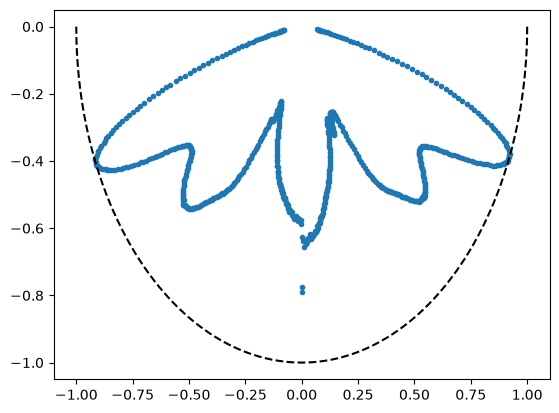

In [6]:
x_port, y_port = np.sin(angs_port[:, 0]), np.cos(angs_port[:, 0])
x_stbd, y_stbd = -np.sin(angs_stbd[:, 0]), np.cos(angs_stbd[:, 0])

ang_true = np.linspace(0, np.pi, 2*ANG_SAMPLES)
x_true, y_true = np.cos(ang_true), np.sin(ang_true)
x, y = np.hstack((angs_port[:, 1] * x_port, angs_stbd[:, 1] * x_stbd)), np.hstack((angs_port[:, 1] * y_port, angs_stbd[:, 1] * y_stbd))

plt.scatter(x, -y, marker='.')
plt.plot(x_true, -y_true, linestyle='--', color='black')
plt.show()

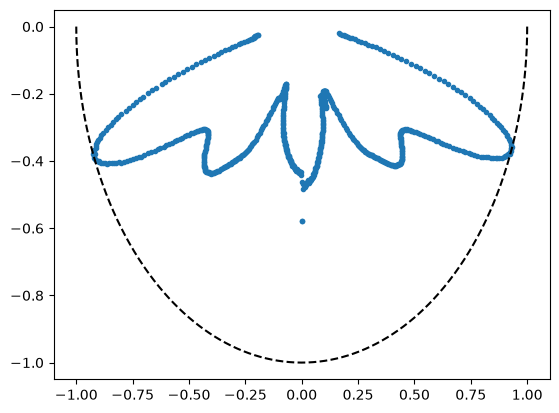

In [7]:
x_port, y_port = np.sin(angs_port[:, 0]), np.cos(angs_port[:, 0])
x_stbd, y_stbd = -np.sin(angs_stbd[:, 0]), np.cos(angs_stbd[:, 0])

ang_true = np.linspace(0, np.pi, 2*ANG_SAMPLES)
x_true, y_true = np.cos(ang_true), np.sin(ang_true)
x, y = np.hstack((angs_port[:, 2] * x_port, angs_stbd[:, 2] * x_stbd)), np.hstack((angs_port[:, 2] * y_port, angs_stbd[:, 2] * y_stbd))

plt.scatter(x, -y, marker='.')
plt.plot(x_true, -y_true, linestyle='--', color='black')
plt.show()

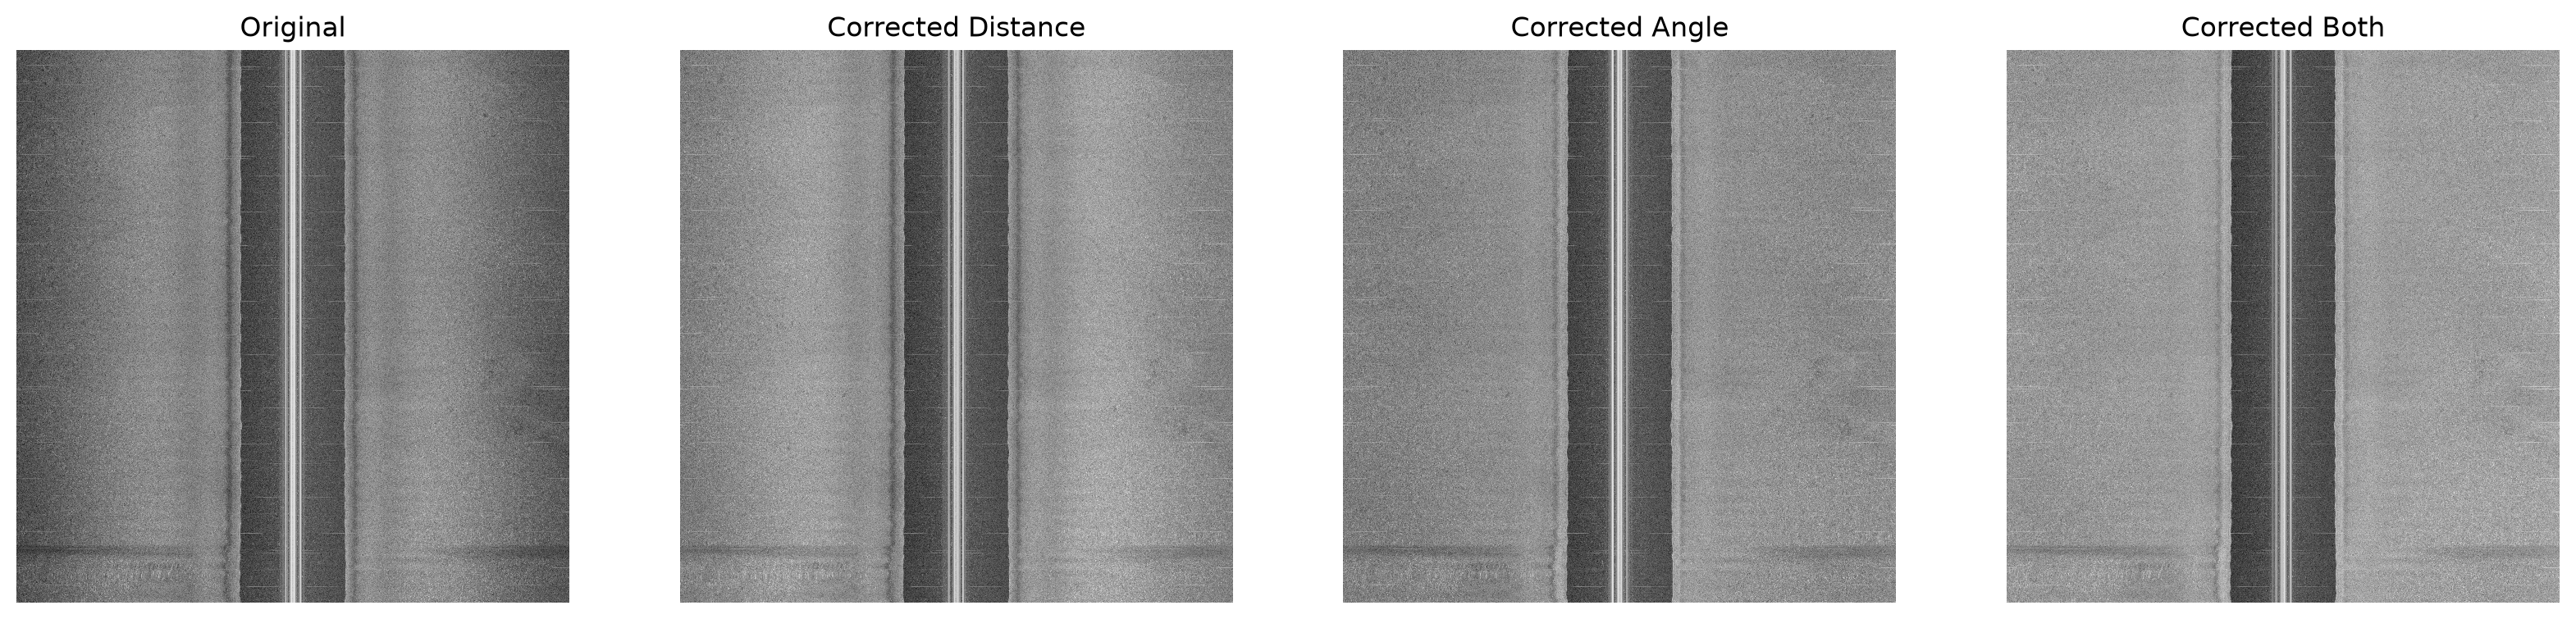

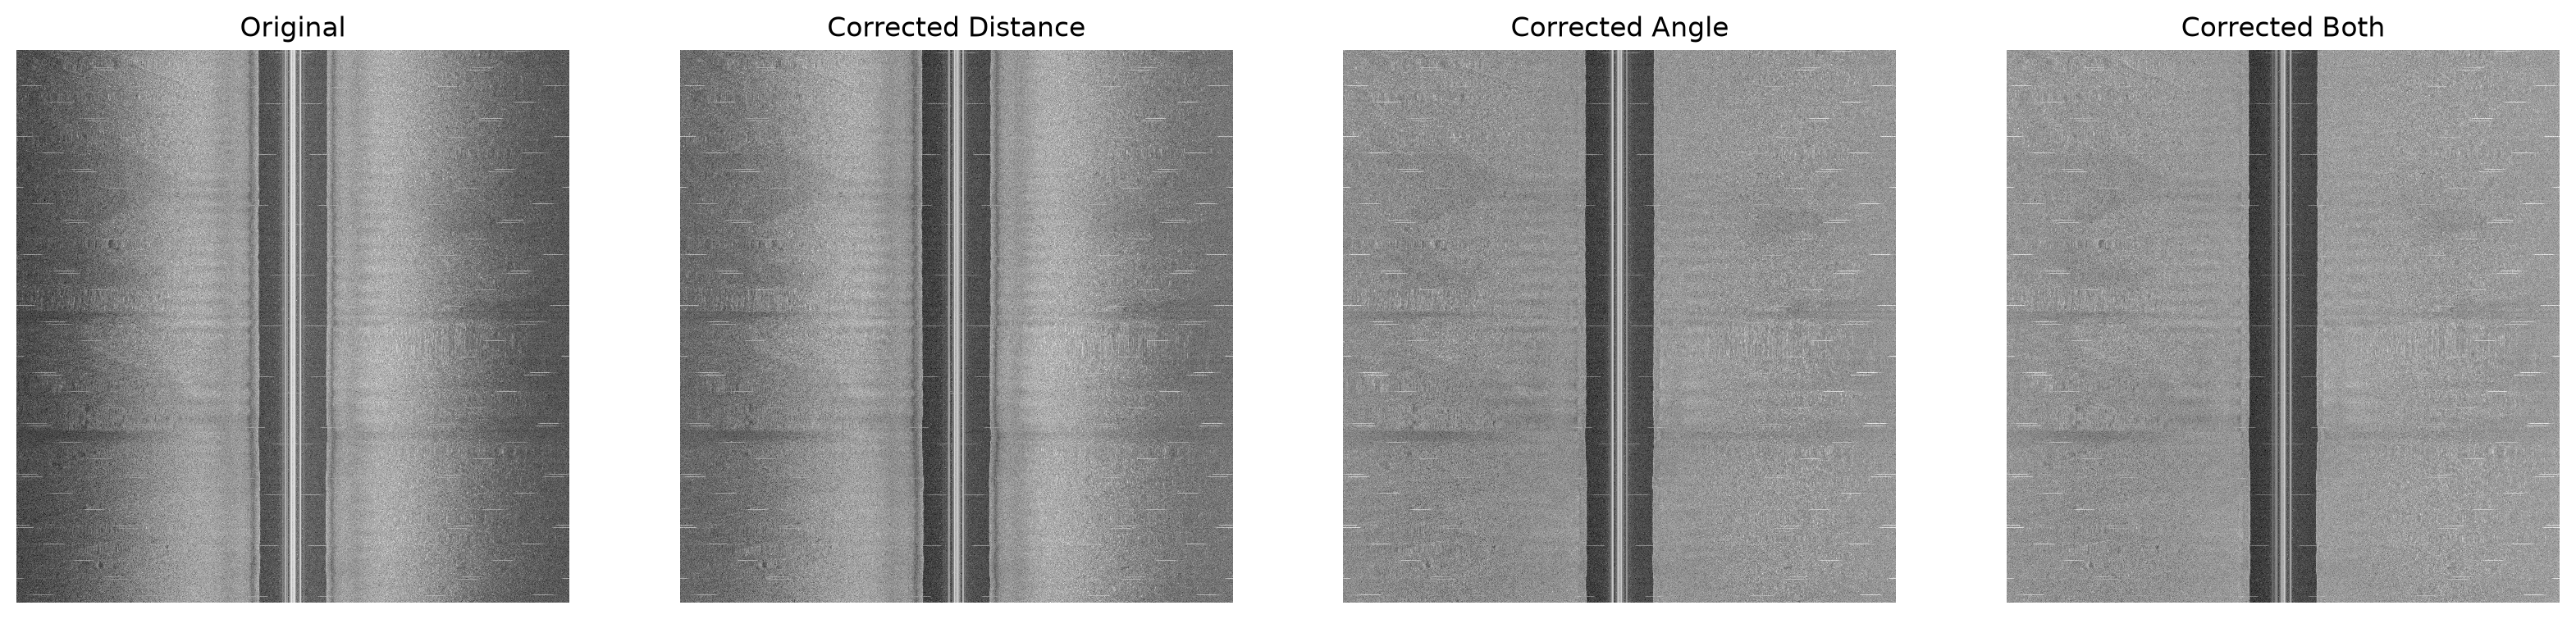

In [9]:
for nav, snr, fbr in ((nav1, snr1, fbr1), (nav2, snr2, fbr2)):
    n_r, n_c = snr.shape

    orig, corr, corr_norm, corr_cols = [], [], [], []
    for row in range(n_r // 2 - NADIR_INDEX, n_r // 2 + NADIR_INDEX):  # An N x N patch from the center of the waterfall
        # Correct altitude using vehicle pitch
        altitude = nav[row].navigation.altitude * np.cos(nav[row].navigation.pitch)

        inds = np.array(list(range(n_c // 2 - fbr[row][0])) + list(range(n_c // 2 + fbr[row][1], n_c)))

        c, c_norm, c_cols = snr[row].copy().astype(np.float32), snr[row].copy().astype(np.float32), snr[row].copy().astype(np.float32)
        for i in inds:
            ang = np.arccos(np.clip(altitude / slants[i], -1, 1))
            gain = angs_port[np.argmin(np.abs(angs_port[:, 0] - ang))] if i < NADIR_INDEX else angs_stbd[np.argmin(np.abs(angs_stbd[:, 0] - ang))]
            c[i] /= gain[1]
            c_cols[i] *= slant_gain[i]
            c_norm[i] = c_cols[i] / gain[2]

        orig.append(snr[row])
        corr.append(c)
        corr_norm.append(c_norm)
        corr_cols.append(c_cols)

    orig = np.log1p(np.array(orig))
    corr = np.log1p(np.array(corr))
    corr_norm = np.log1p(np.array(corr_norm))
    corr_cols = np.log1p(np.array(corr_cols))

    _, axes = plt.subplots(1, 4, figsize=(20, 5), dpi=200)
    for i, (image, title) in enumerate(((orig, "Original"), (corr_cols, "Corrected Distance"), (corr, "Corrected Angle"), (corr_norm, "Corrected Both"))):
        axes[i].imshow(image, cmap='gray', interpolation="none")
        axes[i].set_title(title)
        axes[i].axis('off')
    plt.show()